In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from pathlib import Path 
sns.set_theme(style="whitegrid")
df = pd.read_csv(r"C:\Users\denze\OneDrive\Desktop\Project\New folder\DataCo-Supply-Chain-Analytics\Data\Cleaned\DataCo_Cleaned.csv",
                low_memory=False,
                 parse_dates=[
                     "order_date_dateorders",
                     "shipping_date_dateorders"
                 ]
                )
print("Dataset Shape:",df.shape)
display(df.head())


Dataset Shape: (180519, 58)


,type,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_id,category_name,customer_city,...,order_weekday,order_month_name,shipping_year,shipping_month,delivery_delay_days,delivery_performance,on_time_delivery_flag,profit_margin_pct,loss_flag,order_value_category
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,Wednesday,January,2018,2,-1,Early,1.0,29.001397,0,Medium
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,Saturday,January,2018,1,1,Late,0.0,-80.000645,1,Medium
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,Saturday,January,2018,1,0,On Time,1.0,-80.001291,1,Medium
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,Saturday,January,2018,1,-1,Early,1.0,7.499754,0,Medium
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,Saturday,January,2018,1,-2,Early,1.0,44.999164,0,Medium


In [2]:
required_columns = [
    "order_id",
    "order_item_total",
    "order_profit_per_order",
    "late_delivery_risk",
    "shipping_mode",
    "market",
    "delivery_performance"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

print("Missing Columns:", missing_columns)

Missing Columns: []


In [3]:
# Sales and order performance
total_sales = df["order_item_total"].sum()

total_profit = df["order_profit_per_order"].sum()

total_orders = df["order_id"].nunique()

total_customers = df["customer_id"].nunique()

# Financial performance
profit_margin = (
    total_profit / total_sales * 100
)

average_order_value = (
    total_sales / total_orders
)

# Delivery performance
non_cancelled = df[
    df["delivery_performance"] != "Canceled"
]

late_delivery_rate = (
    non_cancelled["late_delivery_risk"].mean() * 100
)

average_shipping_days = (
    df["days_for_shipping_real"].mean()
)

# Display results
kpis = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Total Profit",
        "Total Orders",
        "Total Customers",
        "Profit Margin (%)",
        "Average Order Value",
        "Late Delivery Rate (%)",
        "Average Shipping Days"
    ],
    "Value": [
        total_sales,
        total_profit,
        total_orders,
        total_customers,
        profit_margin,
        average_order_value,
        late_delivery_rate,
        average_shipping_days
    ]
})

display(kpis.round(2))

,KPI,Value
0,Total Sales,33054402.38
1,Total Profit,3966902.97
2,Total Orders,65752.00
3,Total Customers,20652.00
4,Profit Margin (%),12.00
5,Average Order Value,502.71
6,Late Delivery Rate (%),57.29
7,Average Shipping Days,3.50


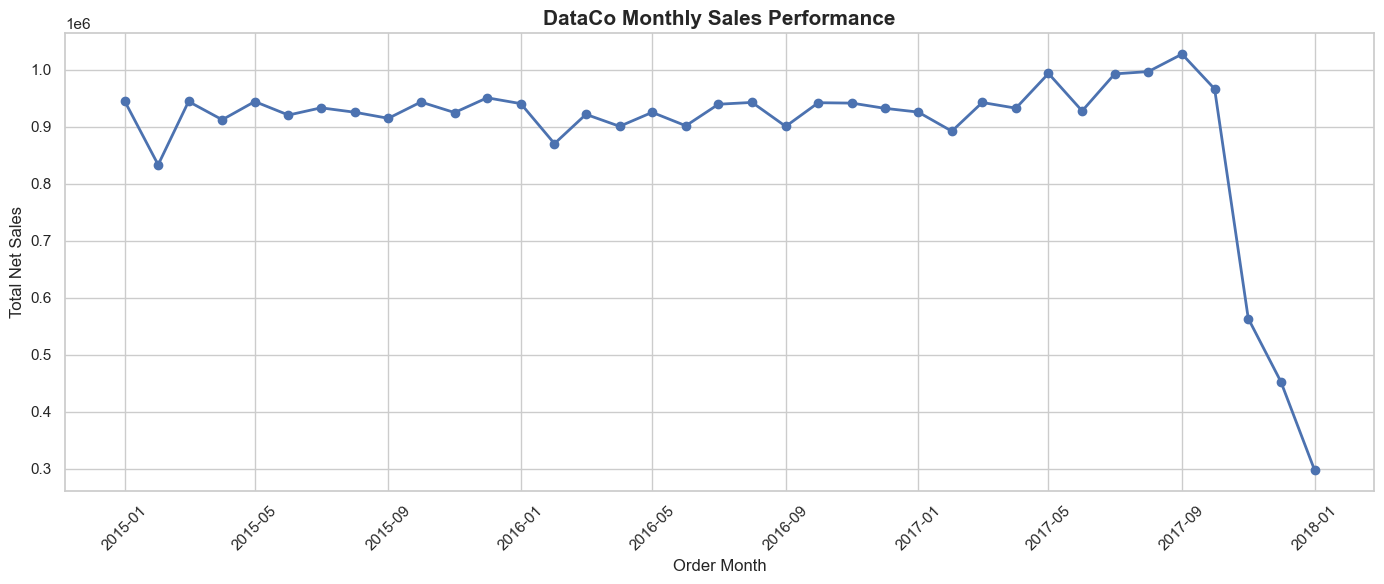

In [4]:
monthly_sales = (
    df.groupby(
        pd.Grouper(
            key="order_date_dateorders",
            freq="MS"
        )
    )["order_item_total"]
    .sum()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title(
    "DataCo Monthly Sales Performance",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Order Month")
plt.ylabel("Total Net Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

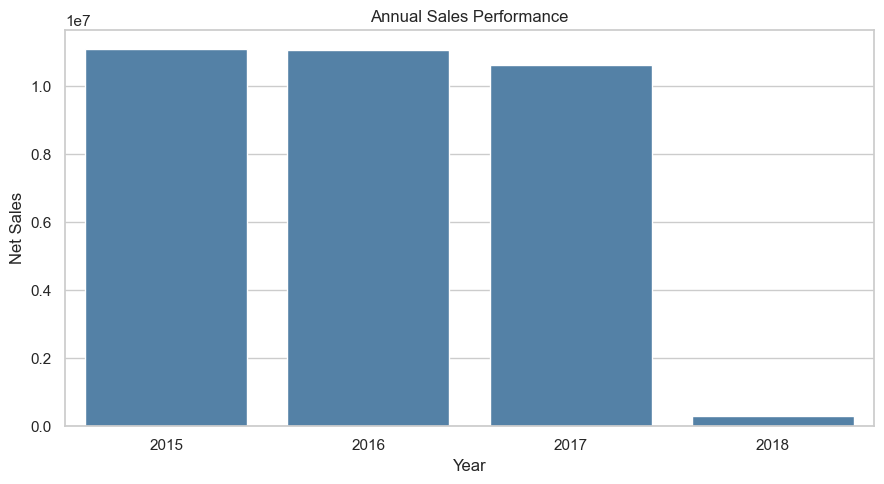

,order_year,order_item_total
0,2015,1.108954e+07
1,2016,1.105600e+07
2,2017,1.061091e+07
3,2018,2.979521e+05


In [5]:
annual_sales = (
    df.groupby("order_year")["order_item_total"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(9,5))

sns.barplot(
    data=annual_sales,
    x="order_year",
    y="order_item_total",
    color="steelblue"
)

plt.title("Annual Sales Performance")
plt.xlabel("Year")
plt.ylabel("Net Sales")
plt.tight_layout() 

plt.show()
display(annual_sales)

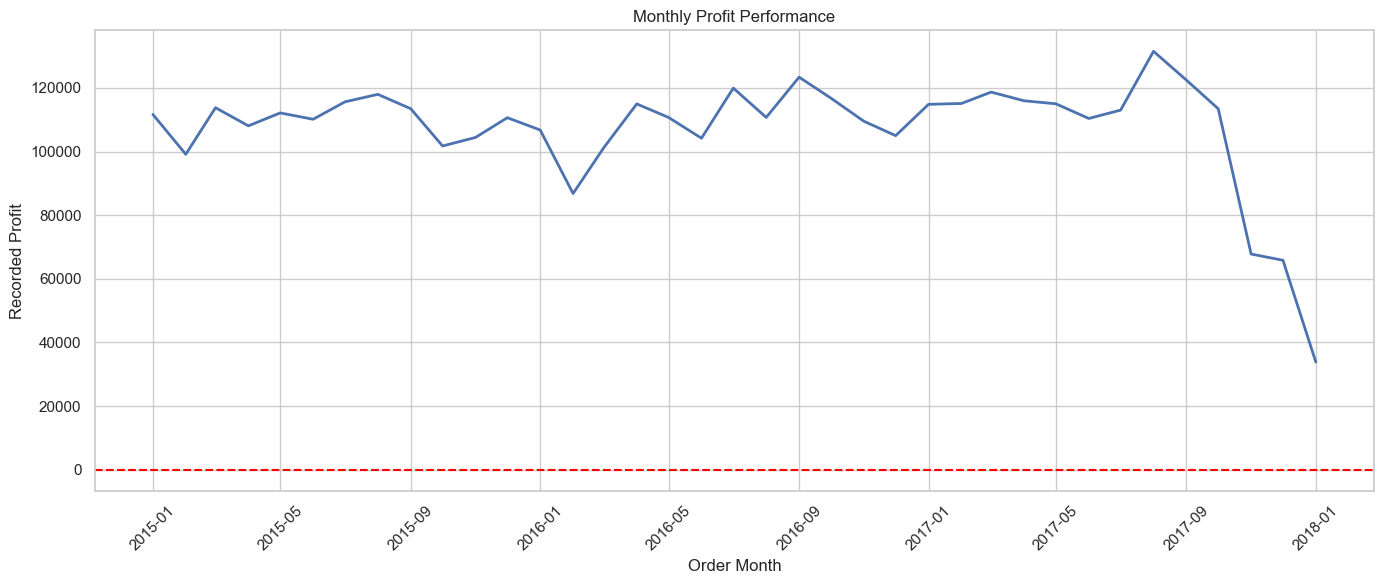

In [6]:
monthly_profit = (
    df.groupby(
        pd.Grouper(
            key="order_date_dateorders",
            freq="MS"
        )
    )["order_profit_per_order"]
    .sum()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_profit.index,
    monthly_profit.values,
    linewidth=2
)

plt.axhline(0, linestyle="--", color="red")

plt.title("Monthly Profit Performance")
plt.xlabel("Order Month")
plt.ylabel("Recorded Profit")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

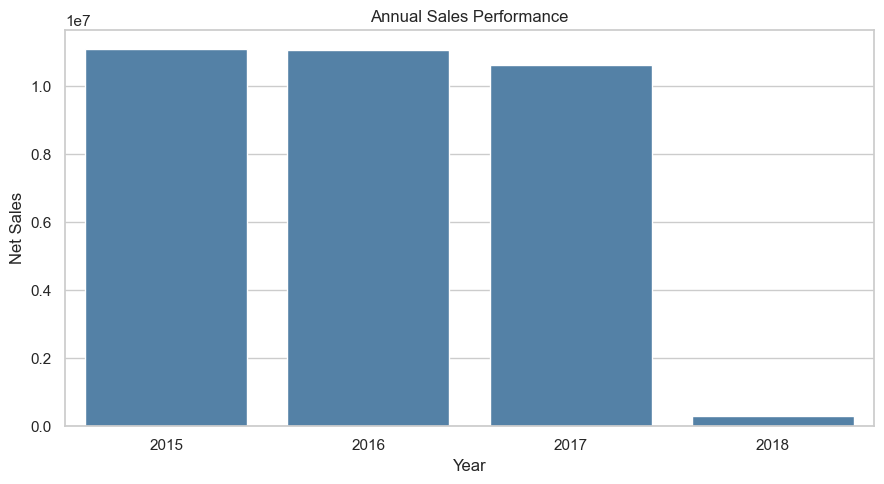

,order_year,order_item_total
0,2015,1.108954e+07
1,2016,1.105600e+07
2,2017,1.061091e+07
3,2018,2.979521e+05


In [7]:
annual_sales = (
    df.groupby("order_year")["order_item_total"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=annual_sales,
    x="order_year",
    y="order_item_total",
    color="steelblue"
)

plt.title("Annual Sales Performance")
plt.xlabel("Year")
plt.ylabel("Net Sales")
plt.tight_layout()

plt.show()

display(annual_sales)

In [9]:
shipping_analysis = (
    df[
        df["delivery_performance"] != "Canceled"
    ]
    .groupby("shipping_mode")
    .agg(
        total_items=("order_item_id", "count"),
        late_deliveries=("late_delivery_risk", "sum"),
        avg_shipping_days=(
            "days_for_shipping_real", "mean"
        ),
        avg_scheduled_days=(
            "days_for_shipment_scheduled", "mean"
        )
    )
    .reset_index()
)

shipping_analysis["late_rate_pct"] = (
    shipping_analysis["late_deliveries"]
    / shipping_analysis["total_items"] * 100
)

display(shipping_analysis.round(2))

,shipping_mode,total_items,late_deliveries,avg_shipping_days,avg_scheduled_days,late_rate_pct
0,First Class,26513,26513,2.00,1.0,100.00
1,Same Day,9293,4454,0.48,0.0,47.93
2,Second Class,33806,26987,3.99,2.0,79.83
3,Standard Class,103153,41023,3.99,4.0,39.77


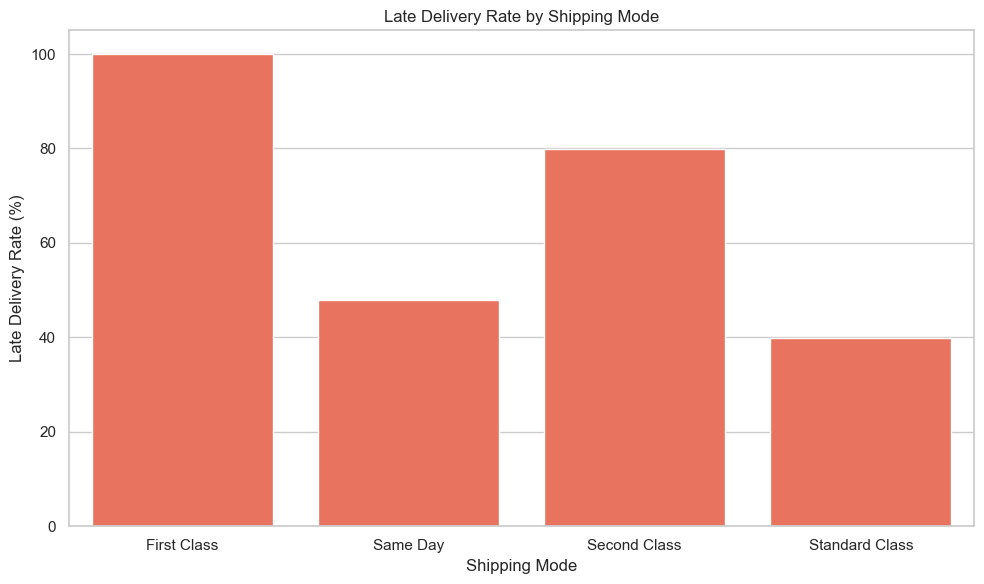

In [10]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=shipping_analysis,
    x="shipping_mode",
    y="late_rate_pct",
    color="tomato"
)

plt.title("Late Delivery Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Late Delivery Rate (%)")
plt.tight_layout()

plt.show()

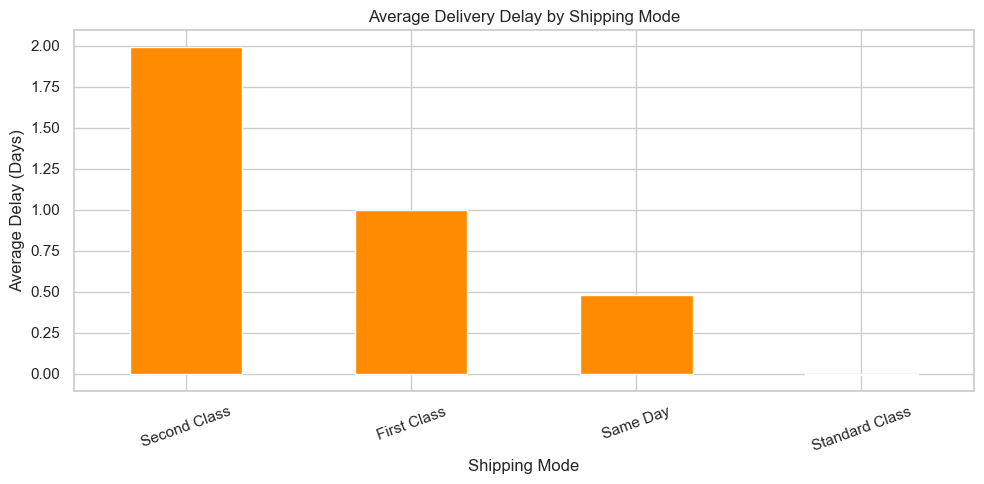

In [11]:
delay_by_mode = (
    df[
        df["delivery_performance"] != "Canceled"
    ]
    .groupby("shipping_mode")[
        "delivery_delay_days"
    ]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

delay_by_mode.plot(kind="bar", color="darkorange")

plt.title("Average Delivery Delay by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Delay (Days)")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

In [12]:
market_performance = (
    df.groupby("market")
    .agg(
        total_sales=("order_item_total", "sum"),
        total_profit=("order_profit_per_order", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

market_performance["profit_margin_pct"] = (
    market_performance["total_profit"]
    / market_performance["total_sales"] * 100
)

display(
    market_performance.sort_values(
        "total_sales",
        ascending=False
    ).round(2)
)

,market,total_sales,total_profit,total_orders,profit_margin_pct
1,Europe,9769198.32,1169442.96,18561,11.97
2,LATAM,9235762.09,1123321.61,17181,12.16
3,Pacific Asia,7434262.65,857753.44,17577,11.54
4,USCA,4553499.92,564313.78,8579,12.39
0,Africa,2061679.39,252071.18,3854,12.23


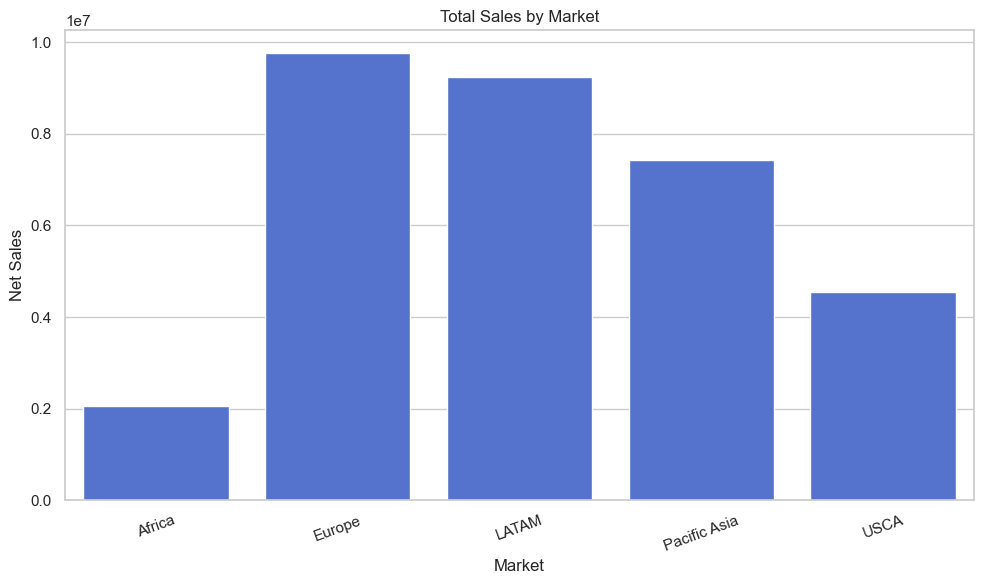

In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=market_performance,
    x="market",
    y="total_sales",
    color="royalblue"
)

plt.title("Total Sales by Market")
plt.xlabel("Market")
plt.ylabel("Net Sales")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

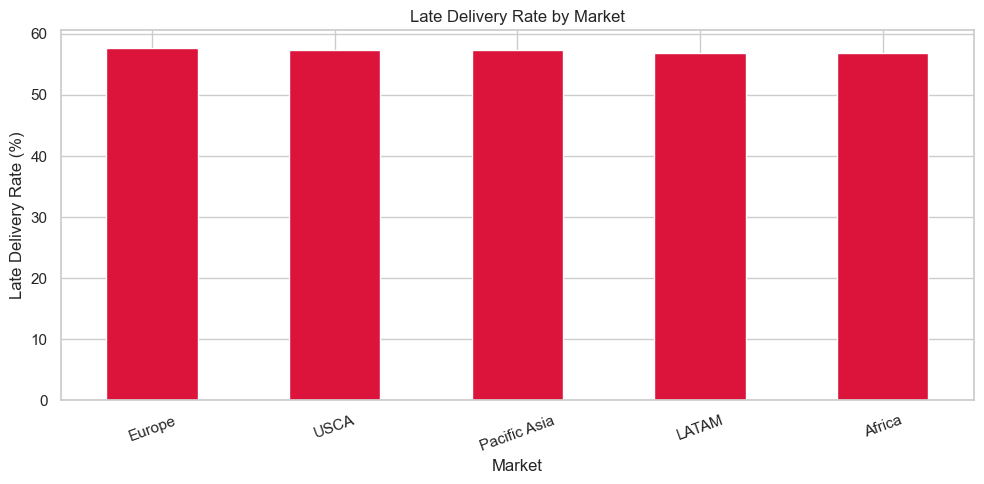

In [14]:
market_delays = (
    df[
        df["delivery_performance"] != "Canceled"
    ]
    .groupby("market")["late_delivery_risk"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

market_delays.plot(kind="bar", color="crimson")

plt.title("Late Delivery Rate by Market")
plt.xlabel("Market")
plt.ylabel("Late Delivery Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

In [15]:
category_performance = (
    df.groupby("category_name")
    .agg(
        total_sales=("order_item_total", "sum"),
        total_profit=("order_profit_per_order", "sum"),
        quantity_sold=("order_item_quantity", "sum")
    )
    .reset_index()
)

category_performance["profit_margin_pct"] = (
    category_performance["total_profit"]
    / category_performance["total_sales"] * 100
)

top_categories = (
    category_performance
    .sort_values("total_sales", ascending=False)
    .head(10)
)

display(top_categories.round(2))

,category_name,total_sales,total_profit,quantity_sold,profit_margin_pct
18,Fishing,6226935.29,756220.77,17325,12.14
12,Cleats,3982856.50,494636.92,73734,12.42
9,Camping & Hiking,3700783.63,427455.57,13729,11.55
10,Cardio Equipment,3320250.70,383011.10,37587,11.54
47,Women's Apparel,2828708.50,350421.03,62956,12.39
46,Water Sports,2798044.18,325146.96,15540,11.62
34,Men's Footwear,2598494.42,311902.82,22246,12.00
30,Indoor/Outdoor Games,2596454.02,318451.43,57803,12.26
38,Shop By Sport,1177185.63,129813.96,32726,11.03
13,Computers,595395.00,69656.81,442,11.70


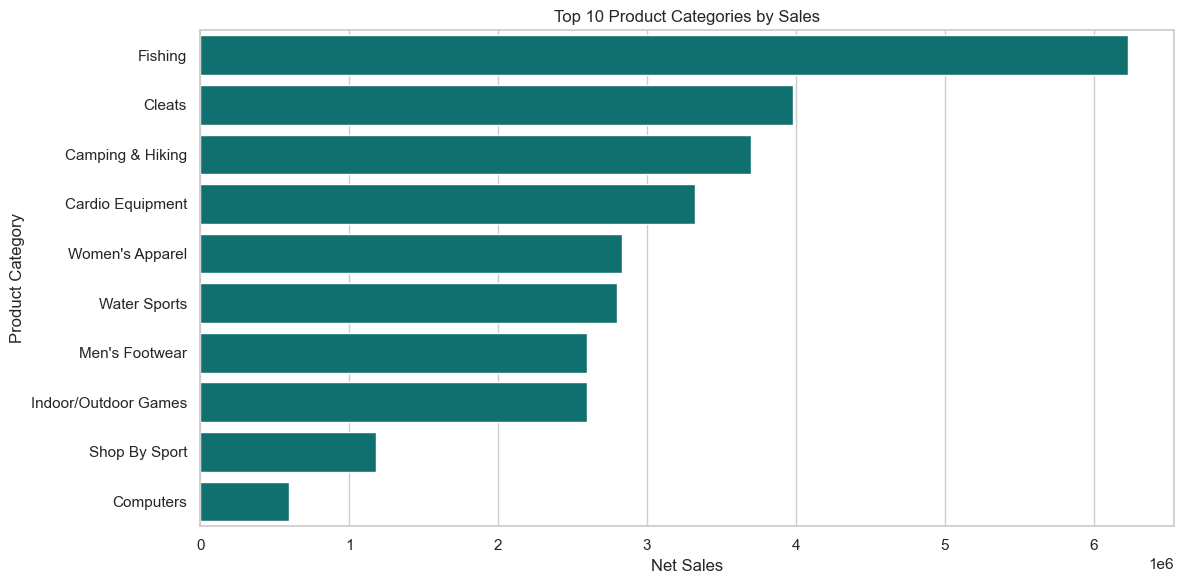

In [16]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categories,
    x="total_sales",
    y="category_name",
    color="teal"
)

plt.title("Top 10 Product Categories by Sales")
plt.xlabel("Net Sales")
plt.ylabel("Product Category")
plt.tight_layout()

plt.show()

In [17]:
loss_categories = (
    category_performance[
        category_performance["total_profit"] < 0
    ]
    .sort_values("total_profit")
)

display(loss_categories)

,category_name,total_sales,total_profit,quantity_sold,profit_margin_pct


In [18]:
customer_segments = (
    df.groupby("customer_segment")
    .agg(
        total_sales=("order_item_total", "sum"),
        total_profit=("order_profit_per_order", "sum"),
        unique_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

display(
    customer_segments.sort_values(
        "total_sales",
        ascending=False
    ).round(2)
)

,customer_segment,total_sales,total_profit,unique_customers,total_orders
0,Consumer,17164278.37,2073487.67,10695,34119
1,Corporate,10030649.90,1202574.96,6239,19856
2,Home Office,5859474.11,690840.34,3718,11777


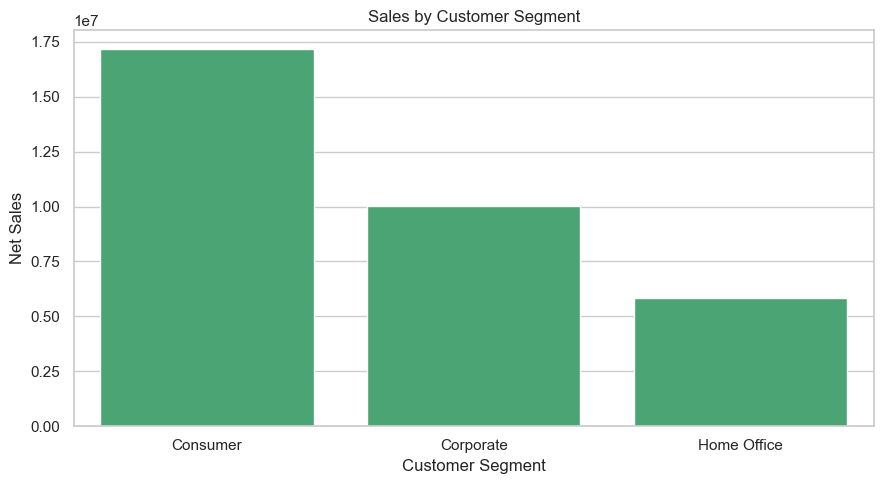

In [19]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=customer_segments,
    x="customer_segment",
    y="total_sales",
    color="mediumseagreen"
)

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Net Sales")
plt.tight_layout()

plt.show()

In [20]:
output_dir = Path("../Data/Cleaned/EDA_Summaries")
output_dir.mkdir(parents=True, exist_ok=True)

annual_sales.to_csv(
    output_dir / "annual_sales.csv",
    index=False
)

shipping_analysis.to_csv(
    output_dir / "shipping_analysis.csv",
    index=False
)

market_performance.to_csv(
    output_dir / "market_performance.csv",
    index=False
)

category_performance.to_csv(
    output_dir / "category_performance.csv",
    index=False
)

customer_segments.to_csv(
    output_dir / "customer_segments.csv",
    index=False
)

print("EDA summaries exported successfully!")

EDA summaries exported successfully!
